<a href="https://colab.research.google.com/github/junelwc6-source/IBM-HR-Attrition-Analytics/blob/main/IBM_HR_Attrition_Capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Part 1 - Descriptive Analytics**


### 1. Project Overview

**Project Title:** Employee Attrition Analysis and Prediction

**BProblem Statement:**

How can employee data be analysed to identify key factors associated with employee attrition, predict employees' likelihood of leaving, and support targeted retention strategies and proactive workforce planning to reduce attrition and minimise staffing gaps?

**Dataset:**

IBM HR Analytics Employee Attrition Dataset, comprising five datasets covering employee demographics, compensation, performance, work experience and employment status.



## 2. Data Understanding

### Objective

To load and examine the five IBM HR Analytics datasets, understand their structure and identify the variables available for employee attrition analysis.

### Data Sources

The analysis uses five datasets:

1. **Employees** – Employee demographics, department and job role.
2. **Compensation** – Salary and compensation information.
3. **Performance** – Job satisfaction, work-life balance and performance indicators.
4. **Experience** – Employment tenure, work experience and career progression.
5. **Employment Status** – Employee attrition and overtime status.



In [2]:

import pandas as pd

# GitHub repository location
base_url = "https://raw.githubusercontent.com/junelwc6-source/IBM-HR-Attrition-Analytics/main/"

# Load datasets directly from GitHub
employees = pd.read_csv(base_url + "Employees.csv")
compensation = pd.read_csv(base_url + "Compensation.csv")
performance = pd.read_csv(base_url + "Performance.csv")
experience = pd.read_csv(base_url + "Experience.csv")
employment_status = pd.read_csv(
    base_url + "Employment%20Status.csv"
)

# Check datasets loaded successfully
print("Employees:", employees.shape)
print("Compensation:", compensation.shape)
print("Performance:", performance.shape)
print("Experience:", experience.shape)
print("Employment Status:", employment_status.shape)


Employees: (1470, 14)
Compensation: (1470, 7)
Performance: (1470, 7)
Experience: (1470, 8)
Employment Status: (1470, 3)


In [3]:

# Check data quality for all five datasets

datasets = {
    "Employees": employees,
    "Compensation": compensation,
    "Performance": performance,
    "Experience": experience,
    "Employment Status": employment_status
}

for name, df in datasets.items():
    print("\n", name)
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate Employee IDs:", df["EmployeeNumber"].duplicated().sum())



 Employees
Missing values: 5
Duplicate Employee IDs: 0

 Compensation
Missing values: 0
Duplicate Employee IDs: 0

 Performance
Missing values: 0
Duplicate Employee IDs: 0

 Experience
Missing values: 0
Duplicate Employee IDs: 0

 Employment Status
Missing values: 0
Duplicate Employee IDs: 0


**Key Observation**

All five datasets contain unique employee records, with no duplicate EmployeeNumbers identified. Five missing values were found in the Employees dataset, while the remaining four datasets had no missing values.

The missing values will be examined and handled in Section 3 — Data Preparation.


## 3. Data Preparation and Feature Engineering

### Objective

To clean and prepare the five datasets, address data quality issues, merge employee records into a single dataset, and create relevant features for descriptive and predictive analysis.

### Data Cleaning

The datasets were checked for missing values and data consistency. Five missing values were identified in the Age column of the Employees dataset. These were replaced with the median age of 36 to retain all employee records for descriptive analysis.


In [4]:

# Identify columns with missing values
print(employees.isnull().sum())

# Display records containing missing values
display(employees[employees.isnull().any(axis=1)])


EmployeeNumber      0
Age                 5
Gender              0
MaritalStatus       0
Education           0
EducationField      0
Department          0
JobRole             0
JobLevel            0
BusinessTravel      0
DistanceFromHome    0
EmployeeCount       0
Over18              0
StandardHours       0
dtype: int64


,EmployeeNumber,Age,Gender,MaritalStatus,Education,EducationField,Department,JobRole,JobLevel,BusinessTravel,DistanceFromHome,EmployeeCount,Over18,StandardHours
5,8,NaN,Male,Single,2,Life Sciences,Research & Development,Laboratory Technician,1,Travel_Frequently,2,1,Y,80
27,35,NaN,Male,Married,4,Marketing,Sales,Sales Executive,2,Travel_Rarely,8,1,Y,80
134,177,NaN,Female,Married,1,Life Sciences,Human Resources,Human Resources,1,Travel_Rarely,25,1,Y,80
262,362,NaN,Male,Single,1,Technical Degree,Research & Development,Laboratory Technician,2,Travel_Rarely,2,1,Y,80
377,501,NaN,Female,Married,3,Life Sciences,Research & Development,Research Scientist,1,Travel_Rarely,2,1,Y,80


In [5]:
# Check the median age before cleaning
print("Median Age:", employees["Age"].median())

# Replace missing ages with the median age
employees["Age"] = employees["Age"].fillna(
    employees["Age"].median()
)

# Verify that no missing values remain
print("Missing Age values after cleaning:",
      employees["Age"].isnull().sum())

Median Age: 36.0
Missing Age values after cleaning: 0


### Missing Age Values — Treatment

Five employees had missing Age values. These were replaced with the median age of 36 to retain all 1,470 employee records for descriptive analysis.

The median was chosen because it is less affected by extreme values than the mean. After replacement, no missing Age values remained.

For predictive modelling, missing Age values will be handled separately within the model's preprocessing pipeline to prevent data leakage.

In [6]:

# Standardise gender values before data integration

employees["Gender"] = (
    employees["Gender"]
    .str.strip()
    .str.lower()
    .replace({
        "m": "male",
        "f": "female",
        "femal": "female"
    })
    .str.title()
)

# Verify cleaned gender categories
print(employees["Gender"].value_counts())


Gender
Male      882
Female    588
Name: count, dtype: int64


In [7]:

# Check whether Employee IDs match across all datasets

employee_ids = set(employees["EmployeeNumber"])

for name, df in datasets.items():
    ids = set(df["EmployeeNumber"])

    print(name)
    print("IDs missing from this dataset:",
          len(employee_ids - ids))
    print("Extra IDs in this dataset:",
          len(ids - employee_ids))
    print()


Employees
IDs missing from this dataset: 0
Extra IDs in this dataset: 0

Compensation
IDs missing from this dataset: 0
Extra IDs in this dataset: 0

Performance
IDs missing from this dataset: 0
Extra IDs in this dataset: 0

Experience
IDs missing from this dataset: 0
Extra IDs in this dataset: 0

Employment Status
IDs missing from this dataset: 0
Extra IDs in this dataset: 0



### Data Integration

The five datasets were validated using EmployeeNumber as the common identifier. All employee IDs matched across the datasets, allowing the records to be merged into a single dataset for analysis.

In [8]:

# Merge the five IBM HR datasets into one master dataframe

df = employees.merge(compensation, on="EmployeeNumber", validate="one_to_one")

df = df.merge(performance, on="EmployeeNumber", validate="one_to_one")

df = df.merge(experience, on="EmployeeNumber", validate="one_to_one")

df = df.merge(employment_status, on="EmployeeNumber", validate="one_to_one")

# Check the merged dataset
print("Merged dataset shape:", df.shape)
print("Duplicate Employee IDs:", df["EmployeeNumber"].duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())

# Display the first 5 rows
display(df.head())


Merged dataset shape: (1470, 35)
Duplicate Employee IDs: 0
Total missing values: 0


,EmployeeNumber,Age,Gender,MaritalStatus,Education,EducationField,Department,JobRole,JobLevel,BusinessTravel,...,WorkLifeBalance,NumCompaniesWorked,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,OverTime
0,1,41.0,Female,Single,2,Life Sciences,Sales,Sales Executive,2,Travel_Rarely,...,1,8,8,0,6,4,0,5,Yes,Yes
1,2,49.0,Male,Married,1,Life Sciences,Research & Development,Research Scientist,2,Travel_Frequently,...,3,1,10,3,10,7,1,7,No,No
2,4,37.0,Male,Single,2,Other,Research & Development,Laboratory Technician,1,Travel_Rarely,...,3,6,7,3,0,0,0,0,Yes,Yes
3,5,33.0,Female,Married,4,Life Sciences,Research & Development,Research Scientist,1,Travel_Frequently,...,3,1,8,3,8,7,3,0,No,Yes
4,7,27.0,Male,Married,1,Medical,Research & Development,Laboratory Technician,1,Travel_Rarely,...,3,9,6,3,2,2,2,2,No,No


### Feature Engineering

Additional grouping variables were created to support employee attrition analysis and interactive reporting in Power BI.

Ten variables were developed to categorise employees by age, income, work experience, company tenure, promotion history, distance from home, job satisfaction, work-life balance, environment satisfaction and relationship satisfaction.

These categories will support comparisons across employee groups and departments, while the original variables are retained for predictive modelling.

In [9]:
# Create age groups for descriptive analysis and Power BI
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 29, 39, 49, float("inf")],
    labels=["Under 30", "30-39", "40-49", "50 and above"]
)

# Verify age group distribution
print(df["AgeGroup"].value_counts().sort_index())

AgeGroup
Under 30        325
30-39           624
40-49           348
50 and above    173
Name: count, dtype: int64


In [10]:

# Create monthly income groups within each department
income_labels = ["Low", "Lower-Middle", "Upper-Middle", "High"]

df["IncomeGroup"] = (
    df.groupby("Department")["MonthlyIncome"]
    .transform(
        lambda x: pd.qcut(
            x.rank(method="first"),
            q=4,
            labels=income_labels
        )
    )
)

# Verify income group distribution
display(
    df.groupby(["Department", "IncomeGroup"], observed=True)
    .size()
    .reset_index(name="Employees")
)


,Department,IncomeGroup,Employees
0,Human Resources,Low,16
1,Human Resources,Lower-Middle,16
2,Human Resources,Upper-Middle,15
3,Human Resources,High,16
4,Research & Development,Low,241
5,Research & Development,Lower-Middle,240
6,Research & Development,Upper-Middle,240
7,Research & Development,High,240
8,Sales,Low,112
9,Sales,Lower-Middle,111


In [11]:

# Create total working experience groups
experience_labels = [
    "0-2 years",
    "3-5 years",
    "6-10 years",
    "11-20 years",
    "More than 20 years"
]

df["ExperienceGroup"] = pd.cut(
    df["TotalWorkingYears"],
    bins=[-1, 2, 5, 10, 20, float("inf")],
    labels=experience_labels
)

# Verify experience group distribution
print(df["ExperienceGroup"].value_counts().sort_index())


ExperienceGroup
0-2 years             123
3-5 years             193
6-10 years            607
11-20 years           340
More than 20 years    207
Name: count, dtype: int64


In [12]:

# Create groups based on years since last promotion
promotion_labels = [
    "0 years",
    "1-2 years",
    "3-5 years",
    "More than 5 years"
]

df["PromotionGroup"] = pd.cut(
    df["YearsSinceLastPromotion"],
    bins=[-1, 0, 2, 5, float("inf")],
    labels=promotion_labels
)

# Verify promotion group distribution
print(df["PromotionGroup"].value_counts().sort_index())


PromotionGroup
0 years              581
1-2 years            516
3-5 years            158
More than 5 years    215
Name: count, dtype: int64


In [13]:

# Create job satisfaction categories for Power BI
satisfaction_labels = {
    1: "Low",
    2: "Medium",
    3: "High",
    4: "Very High"
}

df["SatisfactionGroup"] = df["JobSatisfaction"].map(
    satisfaction_labels
)

# Verify satisfaction categories
print(df["SatisfactionGroup"].value_counts())


SatisfactionGroup
Very High    459
High         442
Low          289
Medium       280
Name: count, dtype: int64


In [14]:

# Create work-life balance categories for Power BI
wlb_labels = {
    1: "Bad",
    2: "Good",
    3: "Better",
    4: "Best"
}

df["WorkLifeBalanceGroup"] = df["WorkLifeBalance"].map(wlb_labels)

# Verify work-life balance categories
print(df["WorkLifeBalanceGroup"].value_counts().sort_index())


WorkLifeBalanceGroup
Bad        80
Best      153
Better    893
Good      344
Name: count, dtype: int64


In [15]:

# Create distance-from-home groups for Power BI
distance_labels = [
    "1-5",
    "6-10",
    "11-20",
    "More than 20"
]

df["DistanceGroup"] = pd.cut(
    df["DistanceFromHome"],
    bins=[0, 5, 10, 20, float("inf")],
    labels=distance_labels
)

# Verify distance group distribution
print(df["DistanceGroup"].value_counts().sort_index())

# Check for unassigned employees
print("Unassigned records:", df["DistanceGroup"].isna().sum())


DistanceGroup
1-5             632
6-10            394
11-20           240
More than 20    204
Name: count, dtype: int64
Unassigned records: 0


In [16]:

# Create company tenure groups for Power BI
tenure_labels = [
    "0-2 years",
    "3-5 years",
    "6-10 years",
    "11-20 years",
    "More than 20 years"
]

df["TenureGroup"] = pd.cut(
    df["YearsAtCompany"],
    bins=[-1, 2, 5, 10, 20, float("inf")],
    labels=tenure_labels
)

# Verify tenure group distribution
print(df["TenureGroup"].value_counts().sort_index())

# Check for unassigned employees
print("Unassigned records:", df["TenureGroup"].isna().sum())


TenureGroup
0-2 years             342
3-5 years             434
6-10 years            448
11-20 years           180
More than 20 years     66
Name: count, dtype: int64
Unassigned records: 0


In [17]:

# Create environment satisfaction categories for Power BI
environment_labels = {
    1: "Low",
    2: "Medium",
    3: "High",
    4: "Very High"
}

df["EnvironmentSatisfactionGroup"] = (
    df["EnvironmentSatisfaction"].map(environment_labels)
)

# Verify environment satisfaction categories
print(df["EnvironmentSatisfactionGroup"].value_counts().sort_index())

# Check for unassigned records
print("Unassigned records:", df["EnvironmentSatisfactionGroup"].isna().sum())


EnvironmentSatisfactionGroup
High         453
Low          284
Medium       287
Very High    446
Name: count, dtype: int64
Unassigned records: 0


In [18]:

# Create relationship satisfaction categories for Power BI
relationship_labels = {
    1: "Low",
    2: "Medium",
    3: "High",
    4: "Very High"
}

df["RelationshipSatisfactionGroup"] = (
    df["RelationshipSatisfaction"].map(relationship_labels)
)

# Verify relationship satisfaction categories
print(df["RelationshipSatisfactionGroup"].value_counts().sort_index())

# Check for unassigned records
print("Unassigned records:",
      df["RelationshipSatisfactionGroup"].isna().sum())


RelationshipSatisfactionGroup
High         459
Low          276
Medium       303
Very High    432
Name: count, dtype: int64
Unassigned records: 0


In [19]:

# Validate feature engineering results
group_columns = [
    "AgeGroup", "IncomeGroup", "ExperienceGroup",
    "PromotionGroup", "SatisfactionGroup",
    "WorkLifeBalanceGroup", "DistanceGroup",
    "TenureGroup", "EnvironmentSatisfactionGroup",
    "RelationshipSatisfactionGroup"
]

print("Total employees:", len(df))
print("Grouping variables created:", len(group_columns))
print("\nMissing values in grouping variables:")
print(df[group_columns].isnull().sum())


Total employees: 1470
Grouping variables created: 10

Missing values in grouping variables:
AgeGroup                         0
IncomeGroup                      0
ExperienceGroup                  0
PromotionGroup                   0
SatisfactionGroup                0
WorkLifeBalanceGroup             0
DistanceGroup                    0
TenureGroup                      0
EnvironmentSatisfactionGroup     0
RelationshipSatisfactionGroup    0
dtype: int64


### Key Findings — Data Preparation

The five datasets were successfully cleaned and merged into a single dataset containing 1,470 employee records.

Ten additional grouping variables were created to support descriptive analysis and interactive reporting in Power BI. All employees were successfully categorised, with no missing values in the newly created variables.

The original employee attributes have been retained for predictive modelling.

## 4. Descriptive and Diagnostic Analysis

### Objective

To examine employee attrition patterns across departments, employee characteristics and workplace factors, and identify groups with higher attrition rates.

### 4.1 Overall Employee Attrition

**Objective:** To establish the overall employee attrition rate as a baseline for subsequent analysis.

In [20]:

# Calculate overall employee attrition

total_employees = len(df)
employees_left = (df["Attrition"] == "Yes").sum()
employees_stayed = (df["Attrition"] == "No").sum()

overall_attrition_rate = (
    employees_left / total_employees * 100
)

print("Total Employees:", total_employees)
print("Employees Left:", employees_left)
print("Employees Stayed:", employees_stayed)
print(f"Overall Attrition Rate: {overall_attrition_rate:.2f}%")


Total Employees: 1470
Employees Left: 237
Employees Stayed: 1233
Overall Attrition Rate: 16.12%



### Key Findings

The dataset contains 1,470 employees, of whom 237 (16.12%) left the organisation, while 1,233 (83.88%) remained.

The overall attrition rate of 16.12% provides a baseline for identifying departments and employee groups with higher attrition rates.

Further analysis will examine the factors associated with employee attrition and identify opportunities for targeted retention strategies.

### 4.2 Departmental Attrition Analysis

**Objective:** To compare attrition rates across departments and identify departments with higher employee attrition.

In [21]:

# Calculate employee attrition by department

department_attrition = (
    df.groupby("Department")["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
)

department_attrition["Attrition_Rate"] = (
    department_attrition["Employees_Left"] /
    department_attrition["Total_Employees"] * 100
).round(2)

department_attrition = department_attrition.sort_values(
    "Attrition_Rate", ascending=False
)

display(department_attrition)


,Total_Employees,Employees_Left,Attrition_Rate
Department,,,
Sales,446,92,20.63
Human Resources,63,12,19.05
Research & Development,961,133,13.84


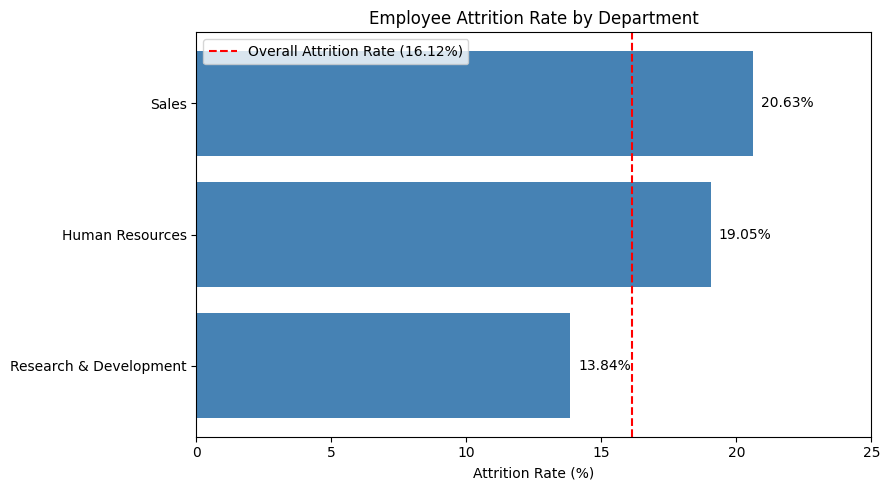

In [22]:

# Visualise attrition rates by department

import matplotlib.pyplot as plt
plt.figure(figsize=(9, 5))

bars = plt.barh(
    department_attrition.index,
    department_attrition["Attrition_Rate"],
    color="steelblue"
)

# Add attrition rate labels
for bar in bars:
    plt.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}%",
        va="center"
    )

# Overall attrition rate as benchmark
plt.axvline(
    overall_attrition_rate,
    color="red",
    linestyle="--",
    label=f"Overall Attrition Rate ({overall_attrition_rate:.2f}%)"
)

plt.title("Employee Attrition Rate by Department")
plt.xlabel("Attrition Rate (%)")
plt.xlim(0, 25)
plt.gca().invert_yaxis()
plt.legend()
plt.tight_layout()
plt.show()



### Key Findings

Sales recorded the highest attrition rate at 20.63% (92 out of 446 employees), followed by Human Resources at 19.05% (12 out of 63 employees). Both departments exceeded the overall attrition rate of 16.12%.

Research & Development recorded the lowest attrition rate at 13.84%. However, it had the highest number of employees who left (133), reflecting its larger workforce.

These findings indicate that Sales and Human Resources have higher relative attrition rates, while Research & Development contributes the largest number of employee departures.

Further analysis will examine the factors associated with attrition within each department to identify potential areas for targeted retention strategies.

### 4.3 Overtime and Employee Attrition

**Objective:** To examine the relationship between overtime and employee attrition across departments.

This analysis explores whether employees working overtime have higher attrition rates and highlights differences across departments.

In [23]:

# Calculate attrition by department and overtime
overtime_attrition = (
    df.groupby(["Department", "OverTime"])["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
    .reset_index()
)

overtime_attrition["Attrition_Rate"] = (
    overtime_attrition["Employees_Left"] /
    overtime_attrition["Total_Employees"] * 100
).round(2)

# Arrange results by department and overtime status
overtime_attrition = overtime_attrition.sort_values(
    ["Department", "OverTime"]
)

display(overtime_attrition)


,Department,OverTime,Total_Employees,Employees_Left,Attrition_Rate
0,Human Resources,No,46,7,15.22
1,Human Resources,Yes,17,5,29.41
2,Research & Development,No,690,59,8.55
3,Research & Development,Yes,271,74,27.31
4,Sales,No,318,44,13.84
5,Sales,Yes,128,48,37.50


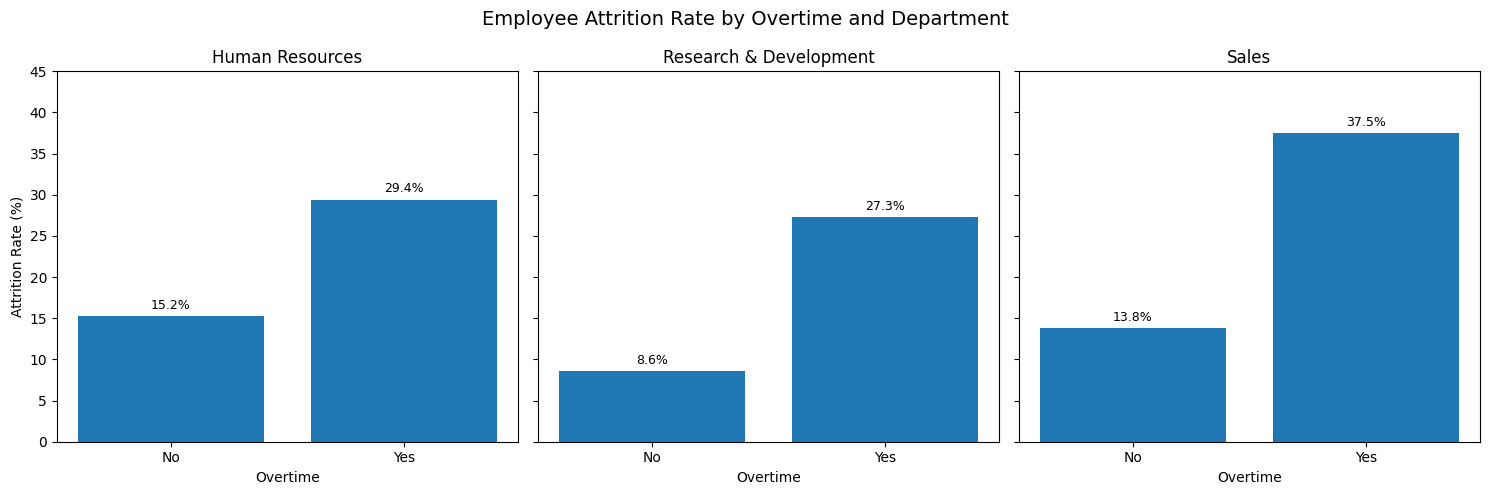

In [24]:

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, dept in zip(axes, departments):
    data = (
        overtime_attrition[
            overtime_attrition["Department"] == dept
        ]
        .set_index("OverTime")
        .reindex(["No", "Yes"])
    )

    bars = ax.bar(
        ["No", "Yes"],
        data["Attrition_Rate"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Overtime")
    ax.set_ylim(0, 45)

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

axes[0].set_ylabel("Attrition Rate (%)")

fig.suptitle(
    "Employee Attrition Rate by Overtime and Department",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Key Findings**

- **Human Resources:** Employees working overtime recorded an attrition rate of 29.41%, compared with 15.22% among those not working overtime.
- **Research & Development:** Employees working overtime had an attrition rate of 27.31%, compared with 8.55% among those not working overtime.
- **Sales:** Employees working overtime recorded the highest attrition rate at 37.50%, compared with 13.84% among those not working overtime.
- **Overall:** Overtime was consistently associated with higher attrition across all three departments, with the largest percentage-point difference observed in Sales. This suggests that workload management and overtime practices should be prioritised for further investigation when developing employee retention strategies.

*Note: These findings show an association between overtime and attrition, but do not establish that overtime causes employees to leave.*

## **Part 2 - Predictive Analystics**

## 5. Predictive Employee Attrition Modelling

### Objective

To develop and evaluate predictive models that estimate the likelihood of employee attrition using employee characteristics, compensation, work experience and workplace-related factors.

The predictive analysis aims to:

1. Identify employees who may be at higher risk of attrition.
2. Evaluate and compare the performance of different predictive models.
3. Identify factors associated with employee attrition risk.
4. Support targeted retention strategies and proactive workforce planning.

### Predictor Selection

Relevant employee and workplace variables will be evaluated to identify factors associated with employee attrition.

Predictors will be selected based on their relevance, data quality and potential contribution to model performance.

The selected variables will be used to develop predictive models that estimate employee attrition risk and support targeted retention strategies.

### Modelling Approach

The analysis will involve:

1. Selecting suitable predictors and preparing the target variable.
2. Splitting the dataset into training and testing sets.
3. Preprocessing numerical and categorical variables.
4. Training and comparing classification models.
5. Evaluating predictive performance using appropriate metrics.
6. Identifying important predictors and generating employee attrition risk probabilities.

Model development and comparison will primarily use training data, with the held-out test data used for final evaluation.

The resulting risk probabilities will support employee-level analysis and interactive drill-through in Power BI.

*Note: The IBM HR dataset is a sample dataset. The predictions demonstrate an analytical approach and should not be treated as validated predictions for actual employees.*

### 5.1 Predictor Selection

**Objective:** To identify suitable variables for predicting employee attrition.

A total of 22 workplace, compensation and career-related variables were selected as candidate predictors. Demographic characteristics, administrative fields and grouping variables created for Power BI were excluded.

The predictive contribution of these variables will be evaluated during model development.

In [25]:

# Section 5.1 - Select predictors for attrition modelling

predictor_columns = [
    "Department",
    "JobRole",
    "JobLevel",
    "BusinessTravel",
    "DistanceFromHome",
    "MonthlyIncome",
    "PercentSalaryHike",
    "StockOptionLevel",
    "PerformanceRating",
    "EnvironmentSatisfaction",
    "JobInvolvement",
    "JobSatisfaction",
    "RelationshipSatisfaction",
    "WorkLifeBalance",
    "NumCompaniesWorked",
    "TotalWorkingYears",
    "TrainingTimesLastYear",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsSinceLastPromotion",
    "YearsWithCurrManager",
    "OverTime"
]

target_column = "Attrition"

# Create modelling dataset
model_df = df[predictor_columns + [target_column]].copy()

# Validate modelling dataset
print("Modelling dataset shape:", model_df.shape)
print("Missing values:", model_df.isnull().sum().sum())

print("\nAttrition distribution:")
print(model_df["Attrition"].value_counts())


Modelling dataset shape: (1470, 23)
Missing values: 0

Attrition distribution:
Attrition
No     1233
Yes     237
Name: count, dtype: int64


### 5.2 Training and Testing Data

**Objective:** To prepare the dataset for predictive modelling and evaluate model performance on unseen data.

The dataset was divided into 80% training data (1,176 employees) and 20% testing data (294 employees).

Stratified sampling was applied to maintain a similar proportion of employees who left the organisation in both datasets. The training data will be used for model development, while the testing data will be reserved for final evaluation.

In [26]:

# Section 5.2 - Prepare data and split into training and testing sets

from sklearn.model_selection import train_test_split

# Separate predictors and target
X = model_df[predictor_columns].copy()
y = model_df["Attrition"].map({"No": 0, "Yes": 1})

# Split data: 80% training and 20% testing
# Stratify to preserve the attrition proportion
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Verify the split
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining attrition distribution:")
print(y_train.value_counts())

print("\nTesting attrition distribution:")
print(y_test.value_counts())


Training records: 1176
Testing records: 294

Training attrition distribution:
Attrition
0    986
1    190
Name: count, dtype: int64

Testing attrition distribution:
Attrition
0    247
1     47
Name: count, dtype: int64


### 5.3 Data Preprocessing

**Objective:** To prepare numerical and categorical variables for predictive modelling.

The 22 selected predictors consist of 18 numerical and 4 categorical variables.

- **Numerical variables:** Missing values are handled using median imputation, followed by standardisation.
- **Categorical variables:** Missing values are handled using the most frequent category, followed by one-hot encoding.

A preprocessing pipeline is used to ensure that transformations are fitted on the training data, reducing the risk of data leakage.

In [27]:

# Section 5.3 - Data preprocessing

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical predictors
categorical_features = [
    "Department",
    "JobRole",
    "BusinessTravel",
    "OverTime"
]

numerical_features = [
    col for col in predictor_columns
    if col not in categorical_features
]

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Verify preprocessing configuration
print("Preprocessing pipeline created successfully.")
print("Numerical predictors:", len(numerical_features))
print("Categorical predictors:", len(categorical_features))
print("Total predictors:", len(predictor_columns))


Preprocessing pipeline created successfully.
Numerical predictors: 18
Categorical predictors: 4
Total predictors: 22


### 5.4 Model Development

**Objective:** To develop and compare classification models for predicting employee attrition.

Two models will be evaluated:

1. **Logistic Regression** — An interpretable model used to establish baseline predictive performance.
2. **Random Forest** — A model capable of identifying more complex relationships between employee and workplace factors.

Both models will use the same preprocessing pipeline and training dataset. Cross-validation will be used to compare model performance before final testing.

In [28]:

# Section 5.4.1 - Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train using training data only
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")
print("Training records:", len(X_train))


Logistic Regression model trained successfully.
Training records: 1176


In [29]:

# Section 5.4.2 - Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train using training data only
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")
print("Training records:", len(X_train))


Random Forest model trained successfully.
Training records: 1176


### 5.5 Model Comparison Using Cross-Validation

**Objective:** To compare the predictive performance of Logistic Regression and Random Forest using training data.

Five-fold stratified cross-validation is used to evaluate both models while maintaining a similar proportion of employees who left in each fold.

The models will be compared using ROC-AUC, recall and F1-score. These metrics help assess how well the models distinguish employees who may leave and identify potential attrition cases.

The test dataset remains reserved for final model evaluation.

In [30]:

# Section 5.5 - Compare models using 5-fold cross-validation

import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Models to compare
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

# Evaluation metrics
scoring = {
    "ROC-AUC": "roc_auc",
    "Recall": "recall",
    "F1-Score": "f1"
}

# Evaluate models using training data only
results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "ROC-AUC": scores["test_ROC-AUC"].mean(),
        "Recall": scores["test_Recall"].mean(),
        "F1-Score": scores["test_F1-Score"].mean()
    })

# Display comparison
cv_results = pd.DataFrame(results)
display(cv_results.round(3))


,Model,ROC-AUC,Recall,F1-Score
0,Logistic Regression,0.831,0.753,0.495
1,Random Forest,0.808,0.463,0.496


#### Key Findings

Logistic Regression achieved a higher ROC-AUC (0.831) and recall (0.753) than Random Forest (0.808 and 0.463 respectively).

Both models recorded similar F1-scores of approximately 0.50.

Based on the cross-validation results, Logistic Regression was selected for further evaluation because of its stronger ability to identify employees who may leave the organisation.

The selected model will be evaluated using the held-out test dataset to assess its performance on unseen data.

### 5.6 Final Model Evaluation

**Objective:** To evaluate the selected Logistic Regression model using unseen testing data.

The model will be assessed using accuracy, precision, recall, F1-score and ROC-AUC.

A confusion matrix will also be used to examine how many employees who left were correctly identified and how many employees were incorrectly predicted to leave.

This evaluation will help determine the model's suitability for identifying employee attrition risk and supporting proactive retention strategies.

In [31]:

# Section 5.6 - Final evaluation of Logistic Regression

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Generate predictions on unseen testing data
y_pred_logistic = logistic_model.predict(X_test)
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

# Calculate performance metrics
final_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Score": [
        accuracy_score(y_test, y_pred_logistic),
        precision_score(y_test, y_pred_logistic, zero_division=0),
        recall_score(y_test, y_pred_logistic, zero_division=0),
        f1_score(y_test, y_pred_logistic, zero_division=0),
        roc_auc_score(y_test, y_prob_logistic)
    ]
})

print("Logistic Regression - Final Test Performance")
display(final_results.round(3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_logistic,
    target_names=["Stayed", "Left"],
    zero_division=0
))



Logistic Regression - Final Test Performance


,Metric,Score
0,Accuracy,0.759
1,Precision,0.370
2,Recall,0.723
3,F1-Score,0.489
4,ROC-AUC,0.795



Confusion Matrix:
[[189  58]
 [ 13  34]]

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.94      0.77      0.84       247
        Left       0.37      0.72      0.49        47

    accuracy                           0.76       294
   macro avg       0.65      0.74      0.67       294
weighted avg       0.85      0.76      0.79       294



#### Key Findings

The Logistic Regression model achieved an accuracy of 75.9%, recall of 72.3% and ROC-AUC of 0.795 on the test dataset.

Of the 47 employees who left, the model correctly identified 34 and missed 13. However, it also incorrectly predicted attrition for 58 employees who stayed, resulting in a precision of 37.0%.

The results indicate that the model can identify a substantial proportion of potential attrition cases, although false-positive predictions remain a limitation.

The model may support early identification of employee attrition risk, but predictions should be used as indicators for further HR review rather than definitive assessments or automatic employment decisions.

### 5.7 Predicted Probability Calibration

**Objective:** To assess whether the model's predicted attrition probabilities are consistent with actual attrition outcomes.

While classification metrics measure how well the model identifies employees who may leave, probability calibration examines whether the predicted likelihood of attrition reflects the observed attrition rate.

The Brier Score will be used to assess probability accuracy, with lower scores indicating better performance.

The results will help determine how the predicted probabilities should be interpreted before developing employee attrition risk categories.

In [51]:

# Section 5.7 - Assess probability calibration

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.base import clone

# Use training data only for calibration assessment
calibration_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate out-of-fold predicted probabilities
train_prob = cross_val_predict(
    clone(logistic_model),
    X_train,
    y_train,
    cv=calibration_cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Calculate calibration metrics
brier_score = brier_score_loss(y_train, train_prob)
roc_auc = roc_auc_score(y_train, train_prob)

print("Logistic Regression - Probability Assessment")
print(f"Brier Score: {brier_score:.3f}")
print(f"ROC-AUC: {roc_auc:.3f}")

print(f"\nActual attrition rate: {y_train.mean():.2%}")
print(f"Average predicted attrition probability: {train_prob.mean():.2%}")

# Compare predicted probabilities with observed attrition
calibration_df = pd.DataFrame({
    "Actual_Attrition": y_train.to_numpy(),
    "Predicted_Probability": train_prob
})

calibration_df["Probability_Group"] = pd.qcut(
    calibration_df["Predicted_Probability"],
    q=5,
    labels=["Q1", "Q2", "Q3", "Q4", "Q5"]
)

calibration_summary = (
    calibration_df.groupby("Probability_Group", observed=True)
    .agg(
        Employees=("Actual_Attrition", "count"),
        Average_Predicted=("Predicted_Probability", "mean"),
        Actual_Attrition_Rate=("Actual_Attrition", "mean")
    )
    .reset_index()
)

display(calibration_summary.round(3))


Logistic Regression - Probability Assessment
Brier Score: 0.160
ROC-AUC: 0.829

Actual attrition rate: 16.16%
Average predicted attrition probability: 36.60%


,Probability_Group,Employees,Average_Predicted,Actual_Attrition_Rate
0,Q1,236,0.040,0.034
1,Q2,235,0.144,0.051
2,Q3,235,0.310,0.077
3,Q4,235,0.538,0.140
4,Q5,235,0.800,0.506


In [52]:
# Section 5.7 - Test calibrated model on unseen data

test_prob_original = logistic_model.predict_proba(X_test)[:, 1]
test_prob_calibrated = calibrated_logistic_model.predict_proba(X_test)[:, 1]

test_results = pd.DataFrame({
    "Measure": ["Brier Score", "ROC-AUC", "Average Predicted Probability"],
    "Original": [
        brier_score_loss(y_test, test_prob_original),
        roc_auc_score(y_test, test_prob_original),
        test_prob_original.mean()
    ],
    "Calibrated": [
        brier_score_loss(y_test, test_prob_calibrated),
        roc_auc_score(y_test, test_prob_calibrated),
        test_prob_calibrated.mean()
    ]
})

display(test_results.round(3))
print(f"Actual Test Attrition Rate: {y_test.mean():.2%}")

,Measure,Original,Calibrated
0,Brier Score,0.162,0.100
1,ROC-AUC,0.795,0.794
2,Average Predicted Probability,0.358,0.156


Actual Test Attrition Rate: 15.99%


#### Key Findings

Probability calibration improved the Logistic Regression model's Brier Score from 0.160 to 0.098 during cross-validation.

The improvement was also confirmed on the unseen test dataset, where the Brier Score decreased from 0.162 to 0.100. The average predicted attrition probability (15.6%) was close to the actual test attrition rate (15.99%).

ROC-AUC remained relatively stable at 0.794 after calibration, indicating that the model maintained its ability to distinguish employees who left from those who stayed.

These findings support using the calibrated Logistic Regression model for subsequent employee attrition risk analysis in Section 6.

*Note: Predicted probabilities are estimates and should not be interpreted as certain employee departures.*

### 5.8 Identifying Important Attrition Predictors

**Objective:** To identify the workplace, compensation and career-related variables that contribute most to predicting employee attrition.

Permutation importance is used to assess the contribution of all 22 predictors to the calibrated Logistic Regression model.

The analysis measures the reduction in ROC-AUC when each predictor is randomly shuffled. A larger reduction indicates that the model relies more heavily on that variable.

Five-fold cross-validation is applied using the training dataset to obtain a more reliable assessment of predictor importance.

The findings will help identify areas for further HR investigation and support targeted employee retention strategies.

*Note: Predictor importance measures contribution to model performance. It does not establish whether a variable causes employee attrition or indicate the direction of its relationship with attrition.*

Predictor Importance Ranking:


,Predictor,Importance
15,TotalWorkingYears,0.0769
21,OverTime,0.0655
1,JobRole,0.0481
3,BusinessTravel,0.0235
7,StockOptionLevel,0.0233
5,MonthlyIncome,0.0192
11,JobSatisfaction,0.0186
20,YearsWithCurrManager,0.0186
19,YearsSinceLastPromotion,0.0176
10,JobInvolvement,0.0156


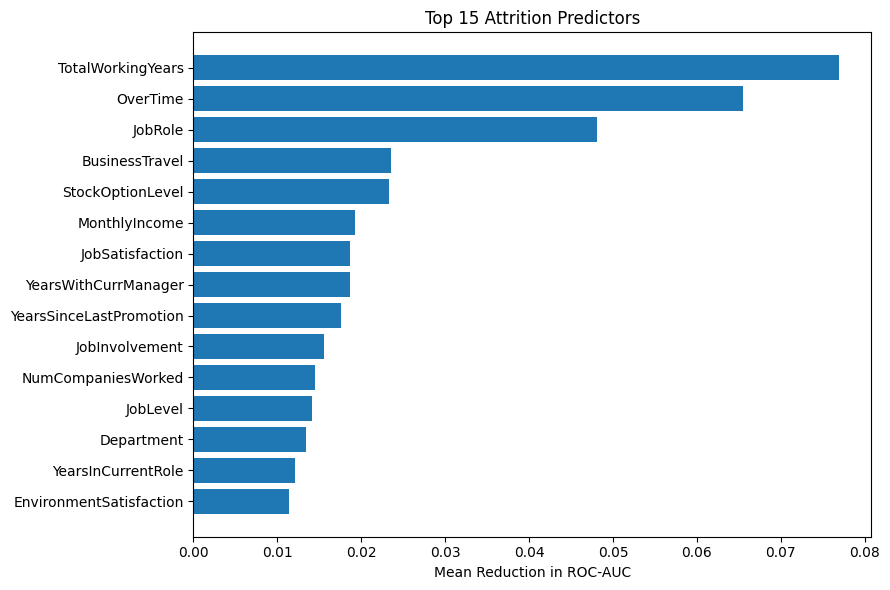

In [53]:

# Section 5.8 - Predictor importance using cross-validation

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold

# Define 5-fold cross-validation
cv_importance = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

importance_results = []

for train_idx, val_idx in cv_importance.split(X_train, y_train):

    # Train a fresh calibrated model for each fold
    model = clone(calibrated_logistic_model)

    model.fit(
        X_train.iloc[train_idx],
        y_train.iloc[train_idx]
    )

    # Calculate importance on unseen validation data
    importance = permutation_importance(
        model,
        X_train.iloc[val_idx],
        y_train.iloc[val_idx],
        scoring="roc_auc",
        n_repeats=5,
        random_state=42,
        n_jobs=-1
    )

    importance_results.append(importance.importances_mean)

# Average importance across validation folds
importance_df = pd.DataFrame({
    "Predictor": predictor_columns,
    "Importance": pd.DataFrame(importance_results).mean(axis=0)
}).sort_values("Importance", ascending=False)

# Display all 22 predictors
print("Predictor Importance Ranking:")
display(importance_df.round(4))

# Visualise the 15 most important predictors
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["Predictor"],
    top_features["Importance"]
)

plt.xlabel("Mean Reduction in ROC-AUC")
plt.title("Top 15 Attrition Predictors")
plt.tight_layout()
plt.show()


#### Key Findings

Permutation importance identified **Total Working Years (0.0769), Overtime (0.0655) and Job Role (0.0481)** as the three most influential predictors in the calibrated Logistic Regression model.

Other important predictors included Business Travel, Stock Option Level, Monthly Income, Job Satisfaction and Years with Current Manager.

These findings suggest that work experience, workload, job responsibilities, compensation and employee satisfaction are relevant areas for further HR investigation.

The results will guide the subsequent employee attrition risk analysis and support the development of targeted retention recommendations.

*Note: Predictor importance reflects the model's reliance on each variable and does not establish causation or indicate whether higher values increase or decrease attrition risk.*

### 6.1 Predicted Attrition Probabilities

**Objective:** To examine the distribution of employee attrition probabilities generated by the calibrated Logistic Regression model.

The calibrated model was applied to the 294 employees in the held-out test dataset to estimate their likelihood of attrition.

The probability distribution will be used to understand variations in predicted attrition risk and support subsequent risk segmentation.

Predicted probabilities represent estimated risk rather than confirmed employee outcomes.

Predicted Attrition Probability Summary:


,Probability
count,294.000
mean,0.156
std,0.175
min,0.003
25%,0.036
50%,0.086
75%,0.217
max,0.879


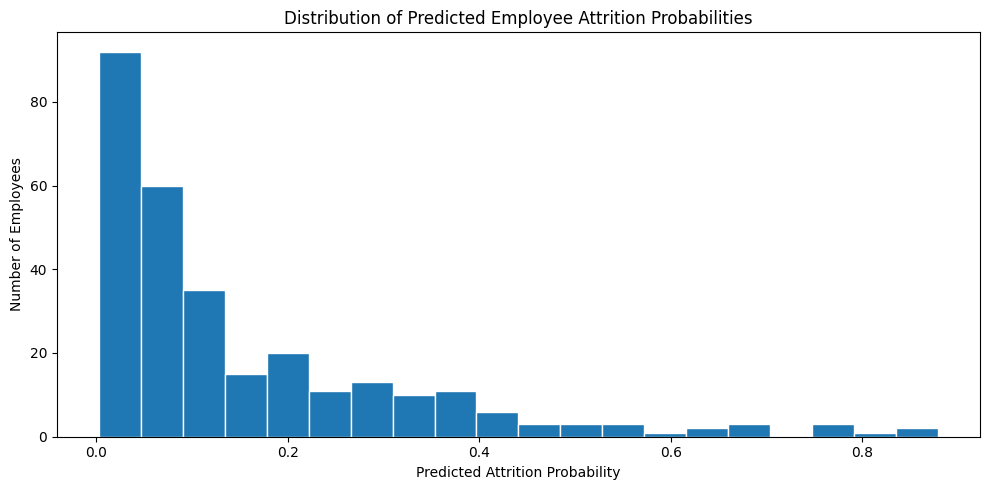

In [35]:

# Section 6.1 - Examine predicted attrition probabilities

import pandas as pd
import matplotlib.pyplot as plt

# Generate calibrated probabilities for the test dataset
y_prob_calibrated = calibrated_logistic_model.predict_proba(X_test)[:, 1]

# Create test dataset containing predictions
risk_df = X_test.copy()

risk_df["EmployeeNumber"] = df.loc[X_test.index, "EmployeeNumber"]
risk_df["Actual_Attrition"] = y_test
risk_df["Predicted_Probability"] = y_prob_calibrated

# Display probability summary
print("Predicted Attrition Probability Summary:")
display(
    risk_df["Predicted_Probability"]
    .describe()
    .round(3)
    .to_frame("Probability")
)

# Visualise probability distribution
plt.figure(figsize=(10, 5))
plt.hist(
    risk_df["Predicted_Probability"],
    bins=20,
    edgecolor="white"
)

plt.title("Distribution of Predicted Employee Attrition Probabilities")
plt.xlabel("Predicted Attrition Probability")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()


#### Key Findings

The calibrated Logistic Regression model generated predicted attrition probabilities for **294 employees in the test dataset**.

- The average predicted attrition probability was **15.6%**, close to the actual test attrition rate of 15.99%.
- The median predicted probability was **8.6%**, indicating that half of the employees had predicted attrition probabilities below this level.
- Predicted probabilities ranged from **0.3% to 87.9%**, showing considerable variation in estimated attrition risk.
- The distribution was right-skewed, with most employees having relatively low predicted probabilities and a smaller group showing higher estimated risk.

These findings support the next stage of analysis, where employees will be grouped into risk categories to identify potential areas for HR investigation.

*Note: Predicted probabilities represent estimated attrition risk, not confirmed future departures.*

### 6.2 Employee Attrition Risk Segmentation

**Objective:** To classify employees into Low, Medium and High relative attrition risk groups using predicted probabilities from the calibrated Logistic Regression model.

Risk thresholds are established using the distribution of out-of-fold predicted probabilities from the training dataset:

- **Low Risk:** At or below the 50th percentile.
- **Medium Risk:** Above the 50th percentile and at or below the 80th percentile.
- **High Risk:** Above the 80th percentile.

These thresholds are subsequently applied to the held-out test dataset to examine employee risk distribution and observed attrition rates.

The categories indicate relative risk within the sample dataset rather than validated clinical or HR intervention thresholds. They are intended to support exploratory workforce analysis and should not be used for automatic employment decisions.</

In [36]:

# Section 6.2 - Employee attrition risk segmentation

import numpy as np
import pandas as pd

# Calculate risk thresholds from training data only
low_threshold = np.quantile(calibrated_train_prob, 0.50)
high_threshold = np.quantile(calibrated_train_prob, 0.80)

print(f"Low / Medium threshold: {low_threshold:.2%}")
print(f"Medium / High threshold: {high_threshold:.2%}")

# Apply training-derived thresholds to test predictions
risk_df["Risk_Level"] = pd.cut(
    risk_df["Predicted_Probability"],
    bins=[-np.inf, low_threshold, high_threshold, np.inf],
    labels=["Low", "Medium", "High"]
)

# Summarise risk groups
risk_summary = (
    risk_df.groupby("Risk_Level", observed=True)
    .agg(
        Employees=("Actual_Attrition", "count"),
        Employees_Left=("Actual_Attrition", "sum"),
        Average_Predicted_Probability=("Predicted_Probability", "mean")
    )
    .reset_index()
)

risk_summary["Actual_Attrition_Rate"] = (
    risk_summary["Employees_Left"] /
    risk_summary["Employees"] * 100
)

risk_summary["Average_Predicted_Probability"] = (
    risk_summary["Average_Predicted_Probability"] * 100
)

display(risk_summary.round(2))

print("\nTotal employees:", risk_summary["Employees"].sum())


Low / Medium threshold: 9.87%
Medium / High threshold: 26.74%


,Risk_Level,Employees,Employees_Left,Average_Predicted_Probability,Actual_Attrition_Rate
0,Low,163,12,4.45,7.36
1,Medium,70,5,16.66,7.14
2,High,61,30,44.20,49.18



Total employees: 294


#### Key Findings

The calibrated Logistic Regression model classified the 294 test employees into three relative risk groups using thresholds derived from training data.

The High Risk group contained 61 employees, of whom 30 left, representing an observed attrition rate of 49.18%. This group accounted for 63.8% of all employees who left in the test dataset.

The Low and Medium Risk groups recorded similar observed attrition rates of 7.36% and 7.14%, respectively. This indicates that the model distinguishes the High Risk group more clearly than it separates the Low and Medium Risk groups.

The findings suggest that risk segmentation may help HR prioritise further investigation and supportive retention initiatives. However, the categories require additional validation before operational use.

### 6.3 Departmental Attrition Risk Analysis

**Objective:** To examine the distribution of predicted employee attrition risk across departments and identify departments with higher proportions of High Risk employees.

The analysis compares Low, Medium and High Risk employee groups across Sales, Human Resources and Research & Development.

It will examine the number and percentage of employees in each risk category, with particular attention to the proportion classified as High Risk.

The findings will support departmental workforce planning and help identify areas for further HR investigation.

*Note: Risk categories are based on model predictions and do not establish the causes of employee attrition.*

In [37]:

# Section 6.3 - Departmental attrition risk analysis

import pandas as pd

# Calculate employee counts by department and risk level
department_risk = (
    risk_df.groupby(
        ["Department", "Risk_Level"],
        observed=True
    )
    .agg(
        Total_Employees=("Actual_Attrition", "count"),
        Employees_Left=("Actual_Attrition", "sum")
    )
    .reset_index()
)

# Calculate total employees in each department
department_totals = (
    risk_df.groupby("Department")
    .size()
    .rename("Department_Total")
    .reset_index()
)

# Add department totals
department_risk = department_risk.merge(
    department_totals,
    on="Department",
    how="left"
)

# Calculate percentage of department employees in each risk level
department_risk["Percentage_of_Department"] = (
    department_risk["Total_Employees"] /
    department_risk["Department_Total"] * 100
).round(2)

# Calculate actual attrition rate within each risk level
department_risk["Observed_Attrition_Rate"] = (
    department_risk["Employees_Left"] /
    department_risk["Total_Employees"] * 100
).round(2)

# Arrange results
department_risk = department_risk[
    [
        "Department",
        "Risk_Level",
        "Total_Employees",
        "Employees_Left",
        "Percentage_of_Department",
        "Observed_Attrition_Rate"
    ]
]

print("Departmental Employee Attrition Risk Distribution:")
display(department_risk)


Departmental Employee Attrition Risk Distribution:


,Department,Risk_Level,Total_Employees,Employees_Left,Percentage_of_Department,Observed_Attrition_Rate
0,Human Resources,Low,8,0,53.33,0.00
1,Human Resources,Medium,4,1,26.67,25.00
2,Human Resources,High,3,1,20.00,33.33
3,Research & Development,Low,118,12,59.90,10.17
4,Research & Development,Medium,52,3,26.40,5.77
5,Research & Development,High,27,14,13.71,51.85
6,Sales,Low,37,0,45.12,0.00
7,Sales,Medium,14,1,17.07,7.14
8,Sales,High,31,15,37.80,48.39


#### Key Findings

Sales recorded the highest proportion of High Risk employees at 37.80% (31 of 82 employees), followed by Human Resources at 20.00% (3 of 15 employees) and Research & Development at 13.71% (27 of 197 employees).

Among High Risk employees, the observed attrition rate was 48.39% in Sales and 51.85% in Research & Development.

Although Research & Development had a lower proportion of High Risk employees, 14 employees in this group left, compared with 15 in Sales.

Human Resources had a small test sample of 15 employees, so its results should be interpreted cautiously.

These findings highlight departmental differences in predicted attrition risk and provide a basis for further investigation into workplace and career-related factors.

### 6.4 High Risk Employee Profiles

**Objective:** To examine the characteristics of employees classified as High Risk and identify patterns that may inform targeted employee retention strategies.

The analysis focuses on High Risk employees across the three departments, examining:

- Total Working Years
- Overtime
- Job Role
- Job Satisfaction
- Monthly Income
- Years Since Last Promotion

These variables were selected based on their relevance to the predictive model and potential usefulness for HR workforce planning.

The findings will help identify employee groups that may benefit from further investigation and supportive retention initiatives.

*Note: These characteristics contribute to the model's risk predictions. Their presence among High Risk employees does not establish that they cause attrition.*

In [38]:

# Section 6.4 - High Risk Employee Profile Analysis

import pandas as pd

# Select employees classified as High Risk
high_risk_df = risk_df[
    risk_df["Risk_Level"] == "High"
].copy()

# Calculate high-risk employee profiles by department
high_risk_profile = (
    high_risk_df.groupby("Department")
    .agg(
        High_Risk_Employees=("Actual_Attrition", "count"),
        Employees_Left=("Actual_Attrition", "sum"),
        Overtime_Employees=("OverTime", lambda x: (x == "Yes").sum()),
        Average_Job_Satisfaction=("JobSatisfaction", "mean"),
        Median_Monthly_Income=("MonthlyIncome", "median"),
        Average_Working_Years=("TotalWorkingYears", "mean"),
        Average_Years_Since_Promotion=("YearsSinceLastPromotion", "mean"),
        Average_Predicted_Risk=("Predicted_Probability", "mean")
    )
    .reset_index()
)

# Calculate overtime percentage
high_risk_profile["Overtime_Percentage"] = (
    high_risk_profile["Overtime_Employees"] /
    high_risk_profile["High_Risk_Employees"] * 100
)

# Convert predicted risk to percentage
high_risk_profile["Average_Predicted_Risk"] *= 100

# Round values
high_risk_profile = high_risk_profile.round(2)

print("High Risk Employee Profiles by Department:")
display(high_risk_profile)


High Risk Employee Profiles by Department:


,Department,High_Risk_Employees,Employees_Left,Overtime_Employees,Average_Job_Satisfaction,Median_Monthly_Income,Average_Working_Years,Average_Years_Since_Promotion,Average_Predicted_Risk,Overtime_Percentage
0,Human Resources,3,1,2,2.33,6410.0,8.00,1.00,39.62,66.67
1,Research & Development,27,14,19,2.63,3348.0,6.81,1.70,38.60,70.37
2,Sales,31,15,17,2.71,3447.0,6.23,1.35,49.52,54.84


#### Key Findings

High Risk employees showed differences in overtime, job satisfaction, working experience and compensation across departments.

Research & Development recorded the highest proportion of High Risk employees working overtime (70.37%), followed by Human Resources (66.67%) and Sales (54.84%).

Sales had the largest High Risk group (31 employees) and the highest average predicted attrition probability (49.52%). Its High Risk employees averaged 6.23 total working years.

These findings highlight workload, working experience and employee satisfaction as areas for further HR investigation.

The Human Resources results should be interpreted cautiously because only three employees were classified as High Risk.

As these characteristics were used in the predictive model, the findings describe model-identified risk profiles rather than establishing the causes of employee attrition.

### 6.5 Employee Profile Comparison Across Risk Levels

**Objective:** To compare employee characteristics across Low, Medium and High predicted attrition risk levels within each department.

The analysis examines overtime, job satisfaction, monthly income and working experience to identify differences between risk groups.

These comparisons will help HR understand the characteristics associated with model-predicted attrition risk and identify areas for further investigation.

*Note: Differences between risk groups are descriptive and do not establish the causes of employee attrition.*

In [39]:

# Section 6.5 - Compare employee profiles across risk levels

risk_profile_comparison = (
    risk_df.groupby(
        ["Department", "Risk_Level"],
        observed=True
    )
    .agg(
        Total_Employees=("Actual_Attrition", "count"),
        Overtime_Employees=("OverTime", lambda x: (x == "Yes").sum()),
        Average_Job_Satisfaction=("JobSatisfaction", "mean"),
        Median_Monthly_Income=("MonthlyIncome", "median"),
        Average_Working_Years=("TotalWorkingYears", "mean")
    )
    .reset_index()
)

# Calculate overtime percentage within each group
risk_profile_comparison["Overtime_Percentage"] = (
    risk_profile_comparison["Overtime_Employees"] /
    risk_profile_comparison["Total_Employees"] * 100
)

# Select columns for presentation
risk_profile_comparison = risk_profile_comparison[
    [
        "Department",
        "Risk_Level",
        "Total_Employees",
        "Overtime_Percentage",
        "Average_Job_Satisfaction",
        "Median_Monthly_Income",
        "Average_Working_Years"
    ]
].round(2)

print("Employee Profiles by Department and Risk Level:")
display(risk_profile_comparison)


Employee Profiles by Department and Risk Level:


,Department,Risk_Level,Total_Employees,Overtime_Percentage,Average_Job_Satisfaction,Median_Monthly_Income,Average_Working_Years
0,Human Resources,Low,8,0.00,2.62,5171.5,16.75
1,Human Resources,Medium,4,25.00,1.75,8435.5,18.75
2,Human Resources,High,3,66.67,2.33,6410.0,8.00
3,Research & Development,Low,118,11.02,2.81,4987.0,13.25
4,Research & Development,Medium,52,30.77,2.73,3570.5,7.69
5,Research & Development,High,27,70.37,2.63,3348.0,6.81
6,Sales,Low,37,18.92,3.05,6694.0,13.32
7,Sales,Medium,14,7.14,2.64,5424.0,10.71
8,Sales,High,31,54.84,2.71,3447.0,6.23


#### Key Findings

The comparison identified differences in overtime, working experience and monthly income across predicted attrition risk groups.

In Research & Development, overtime increased from 11.02% among Low Risk employees to 70.37% among High Risk employees. Average working experience decreased from 13.25 to 6.81 years, while median monthly income decreased from 4,987 to 3,348.

In Sales, High Risk employees also had greater overtime exposure (54.84% compared with 18.92% among Low Risk employees), fewer working years (6.23 compared with 13.32) and lower median monthly income (3,447 compared with 6,694).

Job satisfaction showed some differences between groups, although the pattern was not consistent across all risk levels.

Human Resources results should be interpreted cautiously because of the small sample size.

These findings highlight workload, working experience and compensation as areas for further HR investigation. As these variables contribute to the model's predictions, the comparisons describe model-identified risk profiles rather than independently established causes of attrition.

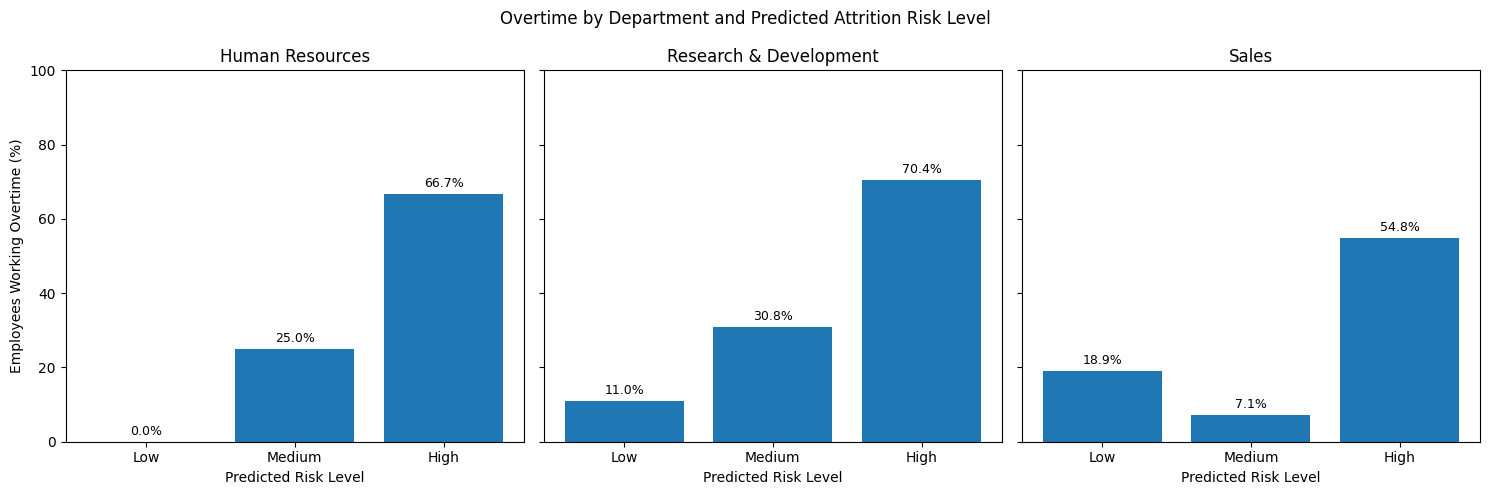

In [40]:

# Section 6.5 - Visualise overtime by department and risk level

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

risk_levels = ["Low", "Medium", "High"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    sharey=True
)

for ax, dept in zip(axes, departments):

    data = (
        risk_profile_comparison[
            risk_profile_comparison["Department"] == dept
        ]
        .set_index("Risk_Level")
        .reindex(risk_levels)
    )

    bars = ax.bar(
        risk_levels,
        data["Overtime_Percentage"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Predicted Risk Level")
    ax.set_ylim(0, 100)

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

axes[0].set_ylabel("Employees Working Overtime (%)")

fig.suptitle(
    "Overtime by Department and Predicted Attrition Risk Level"
)

plt.tight_layout()
plt.show()



### 6.6 Attrition Risk Assessment of Employees Who Stayed

#### Objective

To apply the calibrated Logistic Regression model to the 1,233 employees recorded as having stayed, treating them as an illustrative active workforce.

The assessment aims to:

1. Estimate individual employee attrition risk.
2. Classify employees into Low, Medium and High Risk categories.
3. Identify departments with higher concentrations of High Risk employees.
4. Examine the characteristics of High Risk employees to support targeted HR retention strategies.

**Methodology Note**

The model was developed using historical employee records, including some employees in this illustrative active workforce. Therefore, the resulting risk scores are demonstration estimates rather than independently validated predictions of future departures.

The existing held-out test evaluation remains the basis for reporting predictive model performance.

In [41]:

# Section 6.6.1 — Identify employees who stayed

active_employees = df[df["Attrition"] == "No"].copy()

print("Total employees in historical dataset:", len(df))
print("Employees who stayed:", len(active_employees))
print("Employees who left:", (df["Attrition"] == "Yes").sum())

print("\nEmployees who stayed by department:")
display(active_employees["Department"].value_counts().to_frame("Employees"))


Total employees in historical dataset: 1470
Employees who stayed: 1233
Employees who left: 237

Employees who stayed by department:


,Employees
Department,
Research & Development,828
Sales,354
Human Resources,51


In [42]:

# Section 6.6.2 — Predict attrition risk for employees who stayed

# Use the same 22 predictors as our trained model
X_active = active_employees[X_train.columns].copy()

# Apply the calibrated Logistic Regression model
active_employees["Predicted_Probability"] = (
    calibrated_logistic_model.predict_proba(X_active)[:, 1]
)

print("Employees assessed:", len(active_employees))

print("\nPredicted attrition probability summary:")
display(active_employees["Predicted_Probability"].describe().round(4))

# Preview employee-level predictions
display(
    active_employees[
        ["EmployeeNumber", "Department", "Predicted_Probability"]
    ].head(10)
)


Employees assessed: 1233

Predicted attrition probability summary:


,Predicted_Probability
count,1233.0000
mean,0.1172
std,0.1198
min,0.0008
25%,0.0297
50%,0.0729
75%,0.1671
max,0.6890


,EmployeeNumber,Department,Predicted_Probability
1,2,Research & Development,0.042118
3,5,Research & Development,0.222155
4,7,Research & Development,0.384465
5,8,Research & Development,0.071140
6,10,Research & Development,0.200641
7,11,Research & Development,0.177160
8,12,Research & Development,0.071970
9,13,Research & Development,0.037376
10,14,Research & Development,0.097453
11,15,Research & Development,0.219979


In [43]:

# Section 6.6.3 — Classify employees by attrition risk

active_employees["Risk_Level"] = pd.cut(
    active_employees["Predicted_Probability"],
    bins=[-np.inf, low_threshold, high_threshold, np.inf],
    labels=["Low", "Medium", "High"]
)

# Count employees in each risk category
risk_summary = (
    active_employees["Risk_Level"]
    .value_counts()
    .reindex(["Low", "Medium", "High"])
    .reset_index()
)

risk_summary.columns = ["Risk_Level", "Employees"]
risk_summary["Percentage"] = (
    risk_summary["Employees"] / len(active_employees) * 100
).round(2)

print("Attrition Risk Distribution — Employees Who Stayed")
display(risk_summary)

print(f"Low risk threshold: {low_threshold:.2%}")
print(f"High risk threshold: {high_threshold:.2%}")


Attrition Risk Distribution — Employees Who Stayed


,Risk_Level,Employees,Percentage
0,Low,737,59.77
1,Medium,357,28.95
2,High,139,11.27


Low risk threshold: 9.87%
High risk threshold: 26.74%


In [44]:

# Section 6.6.4 — Departmental attrition risk assessment

department_risk = pd.crosstab(
    active_employees["Department"],
    active_employees["Risk_Level"]
)

department_risk["Total_Employees"] = department_risk.sum(axis=1)

department_risk["High_Risk_Percentage"] = (
    department_risk["High"]
    / department_risk["Total_Employees"] * 100
).round(2)

department_risk = department_risk.sort_values(
    "High_Risk_Percentage",
    ascending=False
)

print("Departmental Attrition Risk — Employees Who Stayed")
display(department_risk)


Departmental Attrition Risk — Employees Who Stayed


Risk_Level,Low,Medium,High,Total_Employees,High_Risk_Percentage
Department,,,,,
Sales,164,128,62,354,17.51
Human Resources,26,18,7,51,13.73
Research & Development,547,211,70,828,8.45


In [45]:

# Section 6.6.5 — Profile of high-risk employees

high_risk_active = active_employees[
    active_employees["Risk_Level"] == "High"
].copy()

high_risk_profile = (
    high_risk_active
    .groupby("Department")
    .agg(
        High_Risk_Employees=("EmployeeNumber", "count"),
        Overtime_Percentage=("OverTime", lambda x: (x == "Yes").mean() * 100),
        Average_Job_Satisfaction=("JobSatisfaction", "mean"),
        Median_Monthly_Income=("MonthlyIncome", "median"),
        Average_Working_Years=("TotalWorkingYears", "mean")
    )
    .round(2)
)

print("High Risk Employee Profile by Department")
display(high_risk_profile)


High Risk Employee Profile by Department


,High_Risk_Employees,Overtime_Percentage,Average_Job_Satisfaction,Median_Monthly_Income,Average_Working_Years
Department,,,,,
Human Resources,7,57.14,2.43,5985.0,10.71
Research & Development,70,60.00,2.57,3443.5,8.57
Sales,62,41.94,2.58,4686.0,8.52


In [46]:

# Section 6.6.6 — Compare employee profiles across risk levels

risk_profile_comparison = (
    active_employees
    .groupby(["Department", "Risk_Level"], observed=True)
    .agg(
        Employees=("EmployeeNumber", "count"),
        Overtime_Percentage=("OverTime", lambda x: (x == "Yes").mean() * 100),
        Average_Job_Satisfaction=("JobSatisfaction", "mean"),
        Median_Monthly_Income=("MonthlyIncome", "median"),
        Average_Working_Years=("TotalWorkingYears", "mean")
    )
    .round(2)
    .reset_index()
)

print("Employee Profile Comparison by Department and Risk Level")
display(risk_profile_comparison)


Employee Profile Comparison by Department and Risk Level


,Department,Risk_Level,Employees,Overtime_Percentage,Average_Job_Satisfaction,Median_Monthly_Income,Average_Working_Years
0,Human Resources,Low,26,19.23,2.92,5070.0,15.96
1,Human Resources,Medium,18,16.67,2.50,3113.5,9.17
2,Human Resources,High,7,57.14,2.43,5985.0,10.71
3,Research & Development,Low,547,13.53,2.88,5363.0,13.16
4,Research & Development,Medium,211,38.39,2.54,3983.0,9.62
5,Research & Development,High,70,60.00,2.57,3443.5,8.57
6,Sales,Low,164,13.41,3.01,6859.0,14.26
7,Sales,Medium,128,25.00,2.66,5656.5,10.01
8,Sales,High,62,41.94,2.58,4686.0,8.52


### Section 6 Summary — Employee Attrition Risk Analysis

The calibrated Logistic Regression model was applied to 294 test employees to estimate attrition probabilities and examine risk patterns across departments.

**Key Findings**

1. **Risk Identification:** The model identified 61 High Risk employees, of whom 30 actually left. This group accounted for 63.8% of all employee departures in the test dataset.

2. **Departmental Risk:** Sales had the highest proportion of High Risk employees (37.80%), followed by Human Resources (20.00%) and Research & Development (13.71%).

3. **Employee Characteristics:** High Risk employees in Sales and Research & Development generally had greater overtime exposure, fewer working years and lower median monthly income than Low Risk employees.

4. **Areas for HR Investigation:** The findings highlight workload, employee experience, compensation and job satisfaction as areas for further investigation and potential retention initiatives.

**Limitations**

The model distinguished High Risk employees more clearly than Low and Medium Risk employees. Risk categories are relative to the sample dataset, and employee characteristics used in the model do not independently establish the causes of attrition.

The analysis uses a sample HR dataset. Further validation using actual organisational data would be necessary before applying the model to workforce decisions.

**Conclusion**

The predictive analysis demonstrates how employee attrition probabilities can support proactive workforce planning by identifying groups that may benefit from further investigation and supportive retention strategies.

The findings provide the basis for the HR recommendations in Section 7.

# **Part 3 — HR Retention Recommendations and Implementation**

## 7. HR Retention Recommendations

### Objective

To translate the findings from descriptive and predictive analytics into practical HR strategies aimed at reducing employee attrition and supporting proactive workforce planning.

The recommendations will focus on workplace factors identified through the analysis, including overtime, working experience, job roles, compensation and employee satisfaction.

Proposed initiatives will be prioritised based on the findings, with consideration given to implementation feasibility and measurable outcomes.

As the analysis is based on a sample HR dataset, the recommendations should be validated through further investigation and pilot initiatives before wider implementation.

### 7.1 Proposed HR Retention Strategies

Based on the descriptive and predictive analyses, the following retention strategies are recommended for further investigation and pilot implementation.

| Key Finding | Recommended HR Action | Departmental Priority | Success Measure |
|---|---|---|---|
| **1. Working experience is the strongest predictive factor.** TotalWorkingYears ranked highest in the model's permutation importance analysis. High Risk employees in Sales and R&D generally had fewer working years. | Strengthen onboarding, mentoring and career development support for less-experienced employees. Introduce structured check-ins and identify early retention concerns. | **Sales and R&D:** Prioritise employee groups with fewer working years and higher attrition risk. | Attrition rate by experience group; 6- and 12-month retention; mentoring participation; onboarding satisfaction. |
| **2. Overtime is a major predictive factor.** Overtime ranked second in permutation importance. High Risk employees in Sales and R&D had substantially greater overtime exposure than Low Risk employees. | Review overtime patterns, staffing levels and workload distribution. Introduce workload reviews and targeted staffing support where excessive overtime is identified. | **Sales and R&D:** Prioritise teams with higher overtime exposure. | Overtime hours per employee; percentage working overtime; attrition rate among employees working overtime. |
| **3. Job role and compensation are relevant to attrition risk.** JobRole and MonthlyIncome were among the model's predictive factors. High Risk employees in Sales and R&D generally had lower median monthly income. | Review attrition patterns by job role, compensation competitiveness and internal pay equity. Examine career progression, recognition and development opportunities. | **Sales and R&D:** Focus on job roles and employee groups with higher observed attrition. | Attrition rate by job role and income group; compensation review completion; internal promotion rate. |
| **4. Employee satisfaction remains an area for investigation.** Job Satisfaction contributed to model predictions, although satisfaction differences across risk groups were not consistent in every department. | Conduct employee pulse surveys and structured feedback sessions. Identify workplace concerns and develop department-specific improvement plans. | **Sales and R&D:** Prioritise teams reporting lower satisfaction or higher observed attrition. | Employee satisfaction score; survey participation; percentage of concerns addressed; employee attrition rate. |
| **5. Sales has the highest departmental attrition concern.** Sales recorded the highest observed attrition rate (20.63%) and highest proportion of High Risk employees in the test dataset (37.80%). | Conduct a focused Sales retention review covering workload, employee feedback, compensation and career development. Pilot suitable interventions and evaluate their effectiveness. | **Sales — Highest Priority** | Sales attrition rate; overtime trends; satisfaction score; 6- and 12-month retention rate. |

### Implementation Considerations

- HR should investigate the underlying reasons for attrition before implementing interventions.
- Recommended initiatives should be piloted and evaluated before organisation-wide rollout.
- Progress should be monitored through regular HR dashboards and management reviews.
- Predictive risk scores should support aggregate workforce planning and voluntary employee support, not be used as the sole basis for individual employment decisions.
- The effectiveness of retention initiatives should be assessed using actual employee outcomes over time.
- The model should be validated using actual organisational data before operational deployment.

**Expected Business Value**

These recommendations provide HR with a structured approach to identifying potential retention concerns, prioritising areas for investigation and evaluating targeted interventions to improve employee retention and support proactive workforce planning.

### 7.2 Implementation and Monitoring Plan

A phased approach is recommended to ensure that retention initiatives are practical, measurable and supported by employee feedback.

| Phase | Proposed Action | Timeline | Expected Output |
|---|---|---|---|
| **1. Investigate** | Review attrition patterns, overtime, employee feedback and working experience, prioritising Sales and higher-risk employee groups. | Months 1–2 | Identification of key retention concerns and priority employee groups. |
| **2. Pilot** | Introduce targeted initiatives such as workload reviews, mentoring, employee engagement and career development support. | Months 3–5 | Pilot retention initiatives implemented in selected teams. |
| **3. Evaluate** | Monitor employee satisfaction, overtime trends, participation and early retention indicators. Compare results against baseline performance. | Months 6–8 | Evaluation of pilot outcomes and identification of areas for improvement. |
| **4. Refine and Scale** | Improve initiatives based on findings and consider extending effective practices to other departments. | Months 9–12 | Updated retention strategies and wider implementation plan. |

**Monitoring and Evaluation**

HR should monitor the following indicators through regular dashboard reporting:

- Overall and departmental employee attrition rates.
- Attrition rates by working experience, job role and income group.
- Overtime exposure and employee satisfaction trends.
- Employee retention at 6 and 12 months.
- Participation and outcomes of retention initiatives.

**Governance Considerations**

Predictive risk scores should be used responsibly to support workforce planning and identify areas for further investigation. HR should review model performance, data quality and potential bias before using predictions in operational decisions.

**Expected Outcome**

The proposed approach aims to help HR move from reactive attrition reporting towards proactive retention management, supported by data analysis, targeted interventions and ongoing evaluation.